# Домашнее задание 3. Логистическая регрессия и Streamlit - Выполнил: Прахов Данил, БПИ246


## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
# Зависимости устанавливаю до запуска ноутбука (см. requirements-hw3.txt).
# Вывожу версии библиотек для воспроизводимости.
import importlib.metadata as metadata
print({name: metadata.version(name) for name in
       ['numpy', 'pandas', 'scikit-learn', 'imbalanced-learn', 'streamlit']})


{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'imbalanced-learn': '0.14.2', 'streamlit': '1.66.1'}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (len(X),) or len(X) == 0:
            raise ValueError('Ожидаются непустые X (N, d) и y (N,)')
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError('В данных есть NaN или бесконечность')
        if not np.isin(y, [0, 1]).all():
            raise ValueError('Метки должны быть 0 или 1')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError('gd_type: full или stochastic')
        if self.eta <= 0 or self.tolerance < 0 or self.max_iter < 1 or self.batch_size < 1:
            raise ValueError('Некорректные параметры спуска')
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        X_bias = np.column_stack([np.ones(len(X)), X])
        self.w = (np.zeros(X_bias.shape[1]) if self.w0 is None
                  else np.asarray(self.w0, dtype=float).copy())
        if self.w.shape != (X_bias.shape[1],) or not np.isfinite(self.w).all():
            raise ValueError('w0 должен быть конечным вектором размера d + 1')
        self.stop_reason_ = 'max_iter'

        for step in range(self.max_iter):
            # История начинается с loss ДО первого обновления весов.
            self.loss_history.append(self.calc_loss(X_bias, y))
            if self.gd_type == 'stochastic':
                ids = rng.choice(len(y), size=min(self.batch_size, len(y)), replace=False)
                gradient = self.calc_gradient(X_bias[ids], y[ids])
            else:
                gradient = self.calc_gradient(X_bias, y)
            new_w = self.w - self.eta * gradient
            delta = np.linalg.norm(new_w - self.w)
            self.w = new_w
            self.n_iter_ = step + 1
            if delta < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break
        self.coef_ = self.w[None, 1:].copy()
        self.intercept_ = self.w[:1].copy()
        return self

    def sigmoid(self, z):
        # logaddexp устойчив и при больших положительных, и при отрицательных z.
        return np.exp(-np.logaddexp(0, -np.asarray(z, dtype=float)))

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise ValueError('Модель ещё не обучена')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != len(self.w) - 1 or not np.isfinite(X).all():
            raise ValueError('Неверная форма X или неконечные значения')
        X_bias = np.column_stack([np.ones(len(X)), X])
        p = self.sigmoid(X_bias @ self.w)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        if not 0 <= threshold <= 1:
            raise ValueError('Порог должен лежать в [0, 1]')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        z = X @ self.w
        # Это та же binary cross-entropy, только без log(0) и переполнения exp.
        return float(np.mean(np.logaddexp(0, z) - y * z))


Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD: 1000 итераций, остановка: max_iter
SGD: 1000 итераций, остановка: max_iter


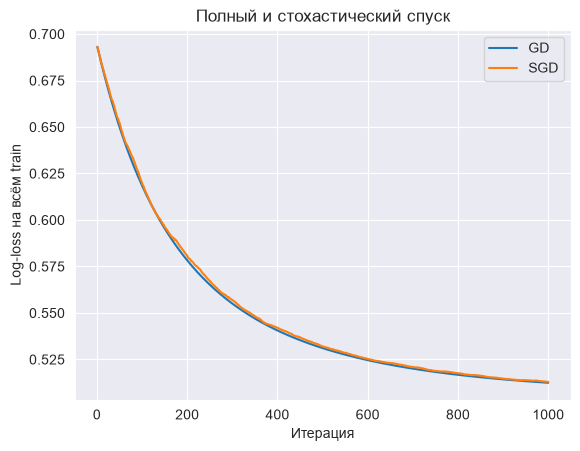

In [6]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
for name, model in [('GD', gd), ('SGD', sgd)]:
    print(f'{name}: {model.n_iter_} итераций, остановка: {model.stop_reason_}')
    plt.plot(np.arange(1, model.n_iter_ + 1), model.loss_history, label=name)
plt.xlabel('Итерация'); plt.ylabel('Log-loss на всём train')
plt.title('Полный и стохастический спуск'); plt.legend(); plt.show()


### Выводы по 1.2
Причина остановки каждого запуска напечатана выше: `tolerance` означает малое изменение весов, `max_iter` — исчерпание бюджета. У SGD градиент шумит из-за случайного батча, поэтому при постоянном шаге веса продолжают колебаться около минимума. Критерий по одному маленькому обновлению для SGD вообще не очень надёжен: оно может оказаться маленьким случайно.

У GD кривая плавнее, у SGD возможны колебания. Для **обновления весов** GD использует 14 000 объектов, SGD — 32. Но в этой реализации оба дополнительно проходят весь train для записи `loss_history`. Поэтому преимущество SGD по стоимости итерации здесь частично теряется: история нужна по условию задания.

В этом запуске обе модели остановились по `max_iter`: по 1000 обновлений. До `tolerance=1e-4` они не дошли.


### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

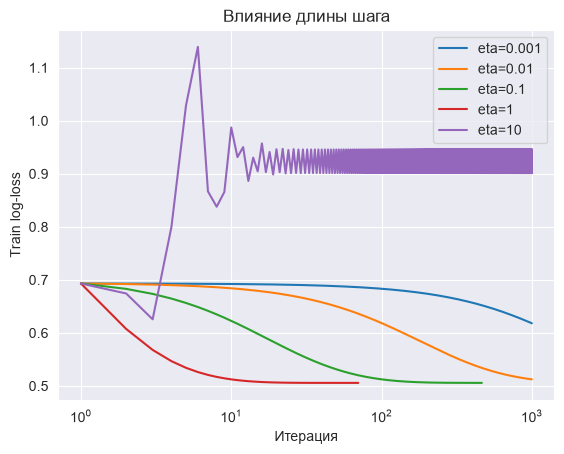

,eta,final_loss,iterations,stop
0,0.001,0.618087,1000,max_iter
1,0.010,0.512435,1000,max_iter
2,0.100,0.505762,465,tolerance
3,1.000,0.505757,70,tolerance
4,10.000,0.901345,1000,max_iter


In [7]:
eta_models = {}
eta_rows = []
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(eta=eta).fit(X_train, y_train)
    eta_models[eta] = model
    # Последний записанный loss относится к весам перед последним шагом.
    final_loss = model.calc_loss(np.column_stack([np.ones(len(X_train)), X_train]), y_train)
    eta_rows.append({'eta': eta, 'final_loss': final_loss,
                     'iterations': model.n_iter_, 'stop': model.stop_reason_})
    plt.plot(np.arange(1, model.n_iter_ + 1), model.loss_history, label=f'eta={eta:g}')
plt.xscale('log'); plt.xlabel('Итерация'); plt.ylabel('Train log-loss')
plt.legend(); plt.title('Влияние длины шага'); plt.show()
eta_table = pd.DataFrame(eta_rows)
display(eta_table)


### Выводы по 1.3
Слишком маленький шаг даёт медленное снижение loss: за фиксированные 1000 итераций модель может просто не успеть сойтись. Умеренный шаг позволяет быстрее приблизиться к минимуму. Большой шаг может перескакивать минимум и вызывать колебания, даже когда loss остаётся конечным. Смотрю на значения функции и форму кривой, а не только на то, сработал ли критерий остановки. Само по себе маленькое изменение весов при маленьком `eta` ещё не доказывает близость к оптимуму.

Численно: при `eta=0.001` loss = 0.6181, при `0.01` — 0.5124. При `0.1` модель остановилась за 465 шагов с loss ≈ 0.5058, при `1` — за 70 шагов с тем же loss. При `10` спуск колеблется и заканчивает с loss ≈ 0.9013: такой шаг здесь слишком велик.


### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sk_model = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
synthetic_rows = []
for name, model in [('GD (default)', gd), ('SGD (default)', sgd), ('sklearn', sk_model)]:
    scores = model.predict_proba(X_test)[:, 1]
    synthetic_rows.append({'model': name, 'accuracy': metrics.accuracy_score(y_test, scores >= 0.5),
                           'ROC-AUC': metrics.roc_auc_score(y_test, scores)})
display(pd.DataFrame(synthetic_rows).set_index('model'))
w_sklearn = np.r_[sk_model.intercept_, sk_model.coef_.ravel()]
display(pd.DataFrame({'GD': gd.w, 'sklearn': w_sklearn, 'difference': gd.w - w_sklearn},
                     index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])]))

# Контрольное сравнение одной и той же задачи, с более строгой сходимостью.
# C=np.inf отключает регуляризацию в используемой версии sklearn.
gd_converged = LogReg(eta=1, max_iter=10000, tolerance=1e-9).fit(X_train, y_train)
sk_unregularized = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10000,
                                      random_state=RANDOM_STATE).fit(X_train, y_train)
w_unreg = np.r_[sk_unregularized.intercept_, sk_unregularized.coef_.ravel()]
print('Максимальная разность весов без регуляризации:', np.max(np.abs(gd_converged.w - w_unreg)))
print('Разность вероятностей:', np.max(np.abs(
    gd_converged.predict_proba(X_test) - sk_unregularized.predict_proba(X_test))))


,accuracy,ROC-AUC
model,,
GD (default),0.7820,0.838787
SGD (default),0.7825,0.838115
sklearn,0.7765,0.838676


,GD,sklearn,difference
intercept,-0.002114,-0.021880,0.019765
x0,0.006076,0.002741,0.003335
x1,0.006963,0.009039,-0.002077
x2,-0.547170,-0.722690,0.175520
x3,-0.144536,-0.262335,0.117799
x4,0.012487,0.016588,-0.004102
x5,-0.006325,-0.011488,0.005163
x6,0.000814,0.005587,-0.004773
x7,0.039084,0.057188,-0.018104
x8,-0.002425,-0.001239,-0.001185


Максимальная разность весов без регуляризации: 8.808671653204314e-09
Разность вероятностей: 9.156098879081753e-09


### Выводы по 1.4
Метрики трёх моделей близки, но равенство не обязано быть точным. В GD/SGD по умолчанию всего 1000 шагов с `eta=0.01`, а в `sklearn` используется другой оптимизатор (`lbfgs`) и L2-регуляризация (`C=1`). Наша функция потерь не содержит штрафа на веса.

Для одной и той же задачи регуляризацию надо отключить: здесь использую `C=np.inf`, а точность и число итераций увеличиваю у обеих моделей. В старых версиях sklearn также использовался `penalty=None`. На этих синтетических данных есть линейно зависимые признаки, поэтому одинаковые прогнозы важнее буквального совпадения весов: без регуляризации коэффициенты в общем случае могут быть неединственны.

Источник: [документация LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

На test accuracy получилась 0.7820 у GD, 0.7825 у SGD и 0.7765 у sklearn; ROC-AUC у всех около 0.838. После отключения регуляризации и строгой сходимости максимальная разность весов составила около $8.8 \cdot 10^{-9}$, а вероятностей — $9.2 \cdot 10^{-9}$. То есть реализация согласуется с контрольной моделью.


## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
from pathlib import Path

# Локальная копия датасета лежит рядом с ноутбуком: интернет для запуска не нужен.
# Второй вариант пути позволяет запускать ноутбук и из корня notebooks/.
data_path = Path('Data/wine_quality.csv')
if not data_path.exists():
    data_path = Path('homework/Data/wine_quality.csv')
df = pd.read_csv(data_path)
assert df.shape[1] == 13 and set(df['target'].unique()) == {0, 1}
print('Data shape:', df.shape)
df.head()


Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Пропуски:', df.isna().sum().sum())
print('Полные дубликаты:', df.duplicated().sum())
print('Prevalence train:', y_train.mean())
print('Prevalence test:', y_test.mean())
# Считаю пересечения одинаковых признаков, чтобы понимать ограничения оценки.
train_hash = pd.util.hash_pandas_object(X_train, index=False)
test_hash = pd.util.hash_pandas_object(X_test, index=False)
print('Строк test с признаками, встречающимися в train:', test_hash.isin(train_hash).sum())

baseline = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
baseline.fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
y_pred = (p_base >= 0.5).astype(int)
print('Accuracy константы:', metrics.accuracy_score(y_test, np.zeros(len(y_test), dtype=int)))
print('Accuracy логистической регрессии:', metrics.accuracy_score(y_test, y_pred))


Пропуски: 0
Полные дубликаты: 1177
Prevalence train: 0.19661315152848033
Prevalence test: 0.19641025641025642
Строк test с признаками, встречающимися в train: 537
Accuracy константы: 0.8035897435897436
Accuracy логистической регрессии: 0.82


### Выводы по 2.1
`stratify=y` сохраняет примерно одинаковую долю хороших вин в train и test. Большинство вин относится к классу 0, поэтому даже константа получает высокую accuracy. Для сервиса такая константа бесполезна: ни одно хорошее вино в подборку не попадёт. Поэтому дальше смотрю precision, recall, F-меры и качество ранжирования.

Повторяющиеся строки есть; число пропусков и доли классов выведены выше. По совпадению лабораторных показателей без идентификатора образца нельзя понять, это повторный замер или ошибка выгрузки. В основном эксперименте сохраняю заданное разбиение и ничего не удаляю после просмотра test. При этом одинаковые строки пересекают train/test, что делает оценку потенциально оптимистичной. Если задача — обобщаться именно на новые независимые образцы, стоит заранее согласовать удаление технических дублей **до разбиения** либо групповое разбиение по образцу. Смешивать эти два протокола в одной таблице нельзя.

В данных 6497 строк, 1177 полных дублей и ни одного пропуска. Prevalence: 19.661% на train и 19.641% на test. У 537 тестовых строк признаки встречаются в train. Accuracy константы — 0.8036, у LR — 0.8200: прибавка всего 1.64 процентного пункта, хотя полезное поведение этих моделей сильно отличается.


### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=98, TN=1501, FP=66, FN=285


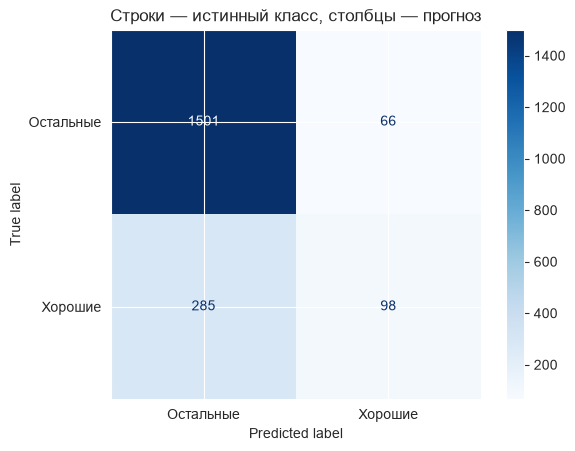

In [12]:
truth = y_test.to_numpy()
TP = int(np.sum((truth == 1) & (y_pred == 1)))
TN = int(np.sum((truth == 0) & (y_pred == 0)))
FP = int(np.sum((truth == 0) & (y_pred == 1)))
FN = int(np.sum((truth == 1) & (y_pred == 0)))
cm_manual = np.array([[TN, FP], [FN, TP]])
assert np.array_equal(cm_manual, metrics.confusion_matrix(y_test, y_pred))
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')
metrics.ConfusionMatrixDisplay(cm_manual, display_labels=['Остальные', 'Хорошие']).plot(cmap='Blues')
plt.title('Строки — истинный класс, столбцы — прогноз'); plt.show()


### Выводы по 2.2
FP — посредственное вино, которое модель включила в подборку: клиент рискует разочароваться. FN — хорошее вино, которое модель пропустила: ассортимент становится беднее. Сравнение количества этих ошибок приведено в матрице выше; при пороге 0.5 модель довольно осторожна и чаще пропускает хорошие вина.

В нашем запуске FP = 66, FN = 285: пропуски хороших вин встречаются заметно чаще. Из 383 хороших вин модель нашла только 98.


### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision_manual = TP / (TP + FP) if TP + FP else 0.0
recall_manual = TP / (TP + FN) if TP + FN else 0.0

def f_manual(beta):
    denominator = beta**2 * precision_manual + recall_manual
    return ((1 + beta**2) * precision_manual * recall_manual / denominator
            if denominator else 0.0)

manual = [precision_manual, recall_manual, f_manual(1), f_manual(0.5), f_manual(2)]
reference = [metrics.precision_score(y_test, y_pred, zero_division=0),
             metrics.recall_score(y_test, y_pred, zero_division=0),
             metrics.fbeta_score(y_test, y_pred, beta=1, zero_division=0),
             metrics.fbeta_score(y_test, y_pred, beta=0.5, zero_division=0),
             metrics.fbeta_score(y_test, y_pred, beta=2, zero_division=0)]
assert np.allclose(manual, reference)
display(pd.DataFrame({'вручную': manual, 'sklearn': reference},
                     index=['precision', 'recall', 'F1', 'F0.5', 'F2']))


,вручную,sklearn
precision,0.597561,0.597561
recall,0.255875,0.255875
F1,0.358318,0.358318
F0.5,0.471607,0.471607
F2,0.288915,0.288915


### Выводы по 2.3
В $F_{0.5}$ больше весит precision, в $F_2$ — recall. Если подписчики болезненно реагируют на посредственные вина, ориентировался бы на $F_{0.5}$: важнее чистота подборки. Для максимально широкой подборки хороших вин выбрал бы $F_2$. $F_1$ — компромисс, когда пока нет численной оценки стоимости двух ошибок. Ни одна F-мера сама по себе не задаёт бизнес-цену ошибки.


### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

,eta,val_log_loss,iterations
0,0.1,0.394803,6000
1,1.0,0.393814,4494


Свой GD: 4848 tolerance


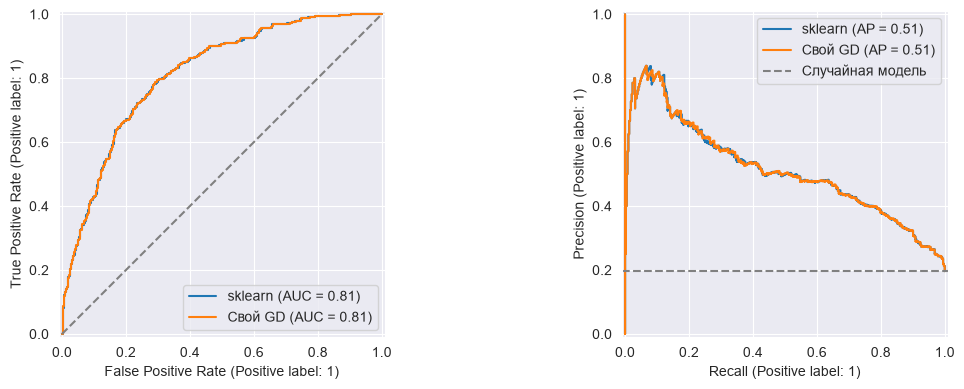

,ROC-AUC,PR-AUC (AP)
model,,
sklearn,0.813537,0.512104
Свой GD,0.813507,0.512212


,ROC-AUC
p,0.813537
10p,0.813537
p^3,0.813537
logit(p),0.813537
-p,0.186463


ROC-AUC по меткам: 0.6068779877399565
PR-AUC случайного ранжирования (базовый уровень): 0.19641025641025642


In [14]:
# Шаг подбираю по log-loss на внутренней валидации.
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
sc_custom = StandardScaler().fit(X_sub)
custom_candidates = []
for eta in [0.1, 1.0]:
    candidate = LogReg(eta=eta, max_iter=6000, tolerance=1e-7).fit(
        sc_custom.transform(X_sub), y_sub)
    custom_candidates.append({'eta': eta, 'val_log_loss': metrics.log_loss(
        y_val, candidate.predict_proba(sc_custom.transform(X_val))),
        'iterations': candidate.n_iter_})
custom_selection = pd.DataFrame(custom_candidates)
display(custom_selection)
best_eta = float(custom_selection.sort_values(['val_log_loss', 'eta']).iloc[0]['eta'])
custom_wine = make_pipeline(StandardScaler(), LogReg(
    eta=best_eta, max_iter=6000, tolerance=1e-7))
custom_wine.fit(X_train, y_train)
p_custom = custom_wine.predict_proba(X_test)[:, 1]
print('Свой GD:', custom_wine[-1].n_iter_, custom_wine[-1].stop_reason_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
auc_rows = []
for name, scores in [('sklearn', p_base), ('Свой GD', p_custom)]:
    metrics.RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])
    auc_rows.append({'model': name, 'ROC-AUC': metrics.roc_auc_score(y_test, scores),
                     'PR-AUC (AP)': metrics.average_precision_score(y_test, scores)})
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[1].axhline(y_test.mean(), ls='--', color='grey', label='Случайная модель')
axes[1].legend(); plt.tight_layout(); plt.show()
auc_table = pd.DataFrame(auc_rows).set_index('model')
display(auc_table)

# logit считаю из decision_function: это log(p / (1 - p)), без округления до 0/1.
transforms = {'p': p_base, '10p': 10 * p_base, 'p^3': p_base**3,
              'logit(p)': baseline.decision_function(X_test), '-p': -p_base}
display(pd.DataFrame({'ROC-AUC': {name: metrics.roc_auc_score(y_test, scores)
                                for name, scores in transforms.items()}}))
print('ROC-AUC по меткам:', metrics.roc_auc_score(y_test, y_pred))
print('PR-AUC случайного ранжирования (базовый уровень):', y_test.mean())


### Выводы по 2.4
Обе модели дают близкое качество: они линейные, но своя реализация обучается без регуляризации. PR-AUC здесь считается как **average precision**, а не как трапеции под PR-кривой.

Преобразования $10p$, $p^3$ и $\log(p/(1-p))$ строго возрастают и сохраняют порядок объектов, поэтому ROC-AUC сохраняется. Для $-p$ порядок разворачивается и AUC становится $1-\mathrm{AUC}(p)$ (с обычным учётом связок). ROC-AUC оценивает ранжирование, а не калибровку вероятностей.

Базовый уровень PR-кривой случайного ранжирования равен prevalence — доле хороших вин, а не 0.5: примерно такая доля отобранных наугад вин будет хорошей. Для конечного случайного ранжирования AP может колебаться вокруг этого ориентира. Если передать в ROC-AUC метки, останется одна рабочая точка с двумя крайними точками ROC; результат равен $(TPR+TNR)/2$. Информация о ранжировании внутри каждого из двух прогнозируемых классов потеряется.

По ROC-AUC совсем немного лучше sklearn: 0.813537 против 0.813507. По AP порядок обратный: свой GD — 0.512212, sklearn — 0.512104. Ранжирование **не совпало**, но различия настолько малы, что содержательного преимущества без оценки неопределённости я бы не заявлял. Базовый уровень PR — 0.196410; ROC-AUC по меткам — 0.606878. Для своей модели на wine выбран `eta=1`: на полном train спуск остановился по `tolerance` за 4848 шагов.


### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

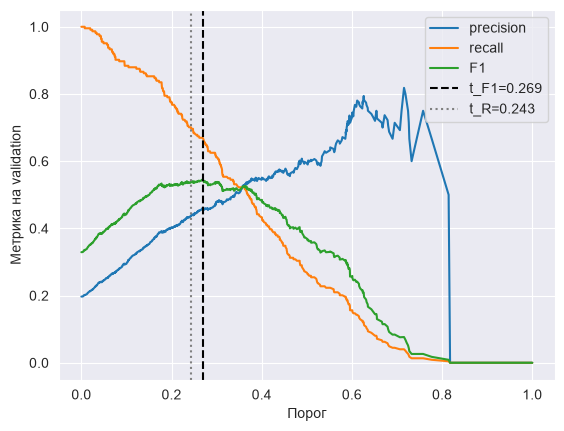

t_F1=0.268889; t_R=0.243196


,model,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,"LR, t=0.5",0.500000,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
1,"LR, t_F1",0.268889,0.789744,0.473888,0.639687,0.544444,0.813537,0.512104
2,"LR, t_R",0.243196,0.765128,0.436975,0.678851,0.531697,0.813537,0.512104


Recall >= 0.7 на test при t_R: False


In [15]:
val_model = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
val_model.fit(X_sub, y_sub)
p_val = val_model.predict_proba(X_val)[:, 1]

# Проверяю все различные разбиения по вероятности, а не только грубую сетку.
# Включаю края [0, 1]; при одинаковом F1 беру более высокий порог.
thresholds = np.unique(np.r_[0.0, p_val, 1.0])
val_rows = []
for t in thresholds:
    pred = p_val >= t
    val_rows.append({'threshold': t,
                     'precision': metrics.precision_score(y_val, pred, zero_division=0),
                     'recall': metrics.recall_score(y_val, pred, zero_division=0),
                     'F1': metrics.f1_score(y_val, pred, zero_division=0)})
val_thresholds = pd.DataFrame(val_rows)
t_F1 = float(val_thresholds.sort_values(['F1', 'threshold'], ascending=[False, False]).iloc[0]['threshold'])
t_R = float(val_thresholds[val_thresholds['recall'] >= 0.7].sort_values(
    ['precision', 'recall', 'threshold'], ascending=[False, False, False]).iloc[0]['threshold'])
for column in ['precision', 'recall', 'F1']:
    plt.plot(val_thresholds['threshold'], val_thresholds[column], label=column)
plt.axvline(t_F1, ls='--', color='black', label=f't_F1={t_F1:.3f}')
plt.axvline(t_R, ls=':', color='grey', label=f't_R={t_R:.3f}')
plt.xlabel('Порог'); plt.ylabel('Метрика на validation'); plt.legend(); plt.show()
print(f't_F1={t_F1:.6f}; t_R={t_R:.6f}')

# Переобучаю модель на всём train с уже выбранными порогами.
baseline.fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]

def model_metrics(name, model, threshold=0.5):
    scores = model.predict_proba(X_test)[:, 1]
    pred = scores >= threshold
    return {'model': name, 'threshold': threshold,
            'accuracy': metrics.accuracy_score(y_test, pred),
            'precision': metrics.precision_score(y_test, pred, zero_division=0),
            'recall': metrics.recall_score(y_test, pred, zero_division=0),
            'F1': metrics.f1_score(y_test, pred, zero_division=0),
            'ROC-AUC': metrics.roc_auc_score(y_test, scores),
            'PR-AUC': metrics.average_precision_score(y_test, scores)}

threshold_table = pd.DataFrame([model_metrics(name, baseline, t) for name, t in
    [('LR, t=0.5', 0.5), ('LR, t_F1', t_F1), ('LR, t_R', t_R)]])
display(threshold_table)
print('Recall >= 0.7 на test при t_R:', bool(threshold_table.iloc[2]['recall'] >= 0.7))


### Выводы по 2.5
Получилось $t_{F_1}=0.268889$ и $t_R=0.243196$. При $t_{F_1}$ на test precision = 0.4739, recall = 0.6397, F1 = 0.5444. При $t_R$ recall = 0.6789: требование 0.7 на тесте не выполнилось.

Пороги подобраны по внутренней валидации. Они не гарантируют те же значения метрик на новых данных: выборки конечны, а после переобучения на всём train немного меняются и вероятности модели. По результатам test пороги не меняю.

Для исходного сценария выбираю $t_{F_1}$ как компромисс между чистотой и полнотой подборки. Если главное — охват хороших вин, больше подходит $t_R$. При высоких потерях от посредственного вина в подборке стоило бы выбирать порог по требованию к precision на валидации.


## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
weighted = make_pipeline(StandardScaler(), LogisticRegression(
    class_weight='balanced', random_state=RANDOM_STATE))
weighted.fit(X_train, y_train)
class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)
display(pd.DataFrame({'train_count': class_counts, 'balanced_weight': class_weights}))
balance_rows = [model_metrics('LR, t=0.5', baseline), model_metrics('LR balanced', weighted)]
display(pd.DataFrame(balance_rows))


,train_count,balanced_weight
target,,
0,3653,0.622365
1,894,2.543065


,model,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,"LR, t=0.5",0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
1,LR balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532


### Выводы по 3.1
Вес класса $k$ равен $n/(K n_k)$, здесь $K=2$. Поэтому каждый хороший образец получает больший вес, а суммарный вес обоих классов становится одинаковым. Значения посчитаны только по train.

Взвешивание сильнее штрафует пропуск хорошего вина, поэтому обычно повышает recall при пороге 0.5 ценой precision и accuracy. ROC-AUC и PR-AUC могут измениться слабее, поскольку оценивают весь порядок объектов, а не один порог. Они всё же не обязаны совпадать: веса меняют оптимизационную задачу, включая наклон разделяющей границы.

Формула: [compute_class_weight в sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html).

Вес класса 0 — 0.622365, класса 1 — 2.543065. Recall вырос с 0.2559 до 0.7546, precision снизился с 0.5976 до 0.3970, accuracy — с 0.8200 до 0.7267. F1 вырос с 0.3583 до 0.5203. ROC-AUC изменился мало: 0.8135 → 0.8113; AP немного снизился: 0.5121 → 0.5005.


### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from sklearn.base import clone
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss v2': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}
resampled_models = {}
resample_counts = []
# Масштабирование перед соседями нужно, иначе расстояния зададут крупные признаки.
scaled_train = StandardScaler().fit_transform(X_train)
for name, sampler in samplers.items():
    _, y_resampled = clone(sampler).fit_resample(scaled_train, y_train)
    counts = pd.Series(y_resampled).value_counts()
    resample_counts.append({'method': name, 'class 0': counts[0], 'class 1': counts[1]})
    model = make_imblearn_pipeline(StandardScaler(), clone(sampler),
                                  LogisticRegression(random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    resampled_models[name] = model
    balance_rows.append(model_metrics(name, model))
display(pd.DataFrame(resample_counts))
balance_table = pd.DataFrame(balance_rows)
display(balance_table)
resample_only = balance_table[balance_table['model'].isin(samplers)]
print('Лучший ресемплинг по test AP:', resample_only.loc[resample_only['PR-AUC'].idxmax(), 'model'])
print('Худший ресемплинг по test AP:', resample_only.loc[resample_only['PR-AUC'].idxmin(), 'model'])

reverse_nearmiss = make_imblearn_pipeline(NearMiss(version=2), StandardScaler(),
                                         LogisticRegression(random_state=RANDOM_STATE))
reverse_nearmiss.fit(X_train, y_train)
display(pd.DataFrame([model_metrics('Scaler → NearMiss', resampled_models['NearMiss v2']),
                      model_metrics('NearMiss → Scaler', reverse_nearmiss)]))
ids_scaled = resampled_models['NearMiss v2'][1].sample_indices_
ids_raw = reverse_nearmiss[0].sample_indices_
print('Общих выбранных объектов:', len(np.intersect1d(ids_scaled, ids_raw)), 'из', len(ids_raw))


,method,class 0,class 1
0,RandomUnderSampler,894,894
1,NearMiss v2,894,894
2,RandomOverSampler,3653,3653
3,SMOTE,3653,3653


,model,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,"LR, t=0.5",0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
1,LR balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
2,RandomUnderSampler,0.5,0.729744,0.401099,0.762402,0.525653,0.809354,0.500779
3,NearMiss v2,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,RandomOverSampler,0.5,0.726667,0.397260,0.757180,0.521114,0.811484,0.500216
5,SMOTE,0.5,0.729231,0.399166,0.749347,0.520871,0.812465,0.503980


Лучший ресемплинг по test AP: SMOTE
Худший ресемплинг по test AP: NearMiss v2


,model,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,Scaler → NearMiss,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
1,NearMiss → Scaler,0.5,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364


Общих выбранных объектов: 1040 из 1788


### Выводы по 3.2
В `imblearn` есть шаг `fit_resample`, который одновременно меняет X и y. Обычный sklearn-пайплайн рассчитан на преобразование X без изменения количества объектов. При `predict` ресемплер пропускается: тест только масштабируется и подаётся в обученную модель. Его размер и распределение классов сохраняются.

Если балансировать до разбиения, копии исходных объектов или SMOTE-точки с общими родителями могут попасть в обе части; к тому же test перестанет отражать реальную prevalence. Это утечка и некорректная оценка.

Удаление большинства класса 0 может терять информацию, а NearMiss ещё и целенаправленно меняет его распределение. Дублирование и SMOTE увеличивают вес редкого класса, но не добавляют независимых наблюдений. У SMOTE бинарный `is_red` может стать дробным: для реального применения стоило бы проверить SMOTENC; здесь оставляю требуемый SMOTE.

Порядок масштабирования **для выбора/генерации объектов** важен у NearMiss и SMOTE: оба используют расстояния. Для случайных under/oversampling при одном seed выбор индексов не зависит от масштаба. Однако итоговые модели могут различаться у всех четырёх методов: scaler до и после ресемплинга оценивает разные средние и дисперсии, а L2-штраф зависит от масштаба признаков. Выше проверил перестановку шагов у NearMiss и число общих выбранных объектов.

Источник: [imblearn Pipeline](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html).

Среди четырёх методов лучший AP у SMOTE — 0.5040, худший у NearMiss v2 — 0.4001. NearMiss сохраняет высокий recall (0.8538), но precision всего 0.2819: отбор большинства явно искажает баланс ошибок. После перестановки NearMiss и scaler AP меняется с 0.4001 до 0.3934, F1 — с 0.4239 до 0.4755; наборы отобранных объектов пересекаются лишь в 1040 из 1788 строк. Это подтверждает чувствительность метода к шкалам признаков.


### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

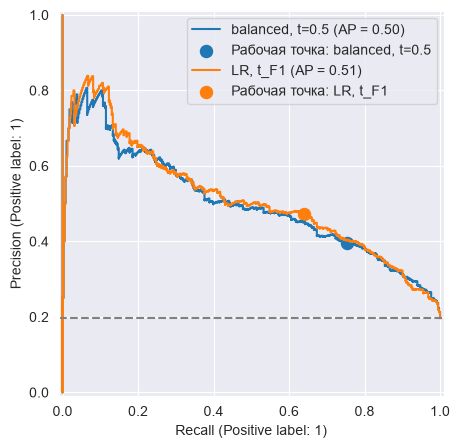

,model,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,LR balanced,0.500000,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
1,"LR, t_F1",0.268889,0.789744,0.473888,0.639687,0.544444,0.813537,0.512104


In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model, threshold in [('balanced, t=0.5', weighted, 0.5), ('LR, t_F1', baseline, t_F1)]:
    scores = model.predict_proba(X_test)[:, 1]
    pred = scores >= threshold
    metrics.PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax)
    ax.scatter(metrics.recall_score(y_test, pred), metrics.precision_score(y_test, pred),
               s=75, marker='o', label=f'Рабочая точка: {name}')
ax.axhline(y_test.mean(), color='grey', ls='--'); ax.legend(); plt.show()
display(pd.DataFrame([model_metrics('LR balanced', weighted),
                      model_metrics('LR, t_F1', baseline, t_F1)]))


### Выводы по 3.3
Изменение порога у обычной LR вообще не меняет PR-кривую, только рабочую точку. Веса классов меняют обучение и могут изменить весь порядок объектов; поэтому две кривые не обязаны совпасть. 

Интуиция про «сдвиг порога» полезна: при идеальном изменении априорных вероятностей классов меняется прежде всего intercept в log-odds. Но на конечных данных, с регуляризацией и неточной линейной моделью могут измениться и остальные коэффициенты. Поэтому точной эквивалентности здесь нет.

Кривые близки, но не идентичны: AP = 0.5005 у balanced и 0.5121 у обычной LR. При своих рабочих порогах balanced даёт precision/recall = 0.3970/0.7546, обычная LR — 0.4739/0.6397. F1 у обычной LR с выбранным порогом выше: 0.5444 против 0.5203.


### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
all_rows = []
# Для константы явно задаю и метки, и непрерывную оценку 0.
constant_scores = np.zeros(len(y_test))
all_rows.append({'model': 'Константа 0', 'threshold': 0.5,
                 'accuracy': metrics.accuracy_score(y_test, constant_scores),
                 'precision': 0.0, 'recall': 0.0, 'F1': 0.0,
                 'ROC-AUC': metrics.roc_auc_score(y_test, constant_scores),
                 'PR-AUC': metrics.average_precision_score(y_test, constant_scores)})
all_rows += threshold_table.to_dict('records')
all_rows += [model_metrics('Свой GD', custom_wine), model_metrics('LR balanced', weighted)]
all_rows += [model_metrics(name, model) for name, model in resampled_models.items()]
all_rows += [model_metrics('NearMiss → Scaler', reverse_nearmiss)]
all_metrics = pd.DataFrame(all_rows).set_index('model')
display(all_metrics)
final_model = baseline
final_threshold = t_F1
print('Итоговая модель: StandardScaler + LogisticRegression, threshold =', final_threshold)


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
Константа 0,0.500000,0.803590,0.000000,0.000000,0.000000,0.500000,0.196410
"LR, t=0.5",0.500000,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
"LR, t_F1",0.268889,0.789744,0.473888,0.639687,0.544444,0.813537,0.512104
"LR, t_R",0.243196,0.765128,0.436975,0.678851,0.531697,0.813537,0.512104
Свой GD,0.500000,0.821538,0.603550,0.266319,0.369565,0.813507,0.512212
LR balanced,0.500000,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
RandomUnderSampler,0.500000,0.729744,0.401099,0.762402,0.525653,0.809354,0.500779
NearMiss v2,0.500000,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
RandomOverSampler,0.500000,0.726667,0.397260,0.757180,0.521114,0.811484,0.500216


Итоговая модель: StandardScaler + LogisticRegression, threshold = 0.2688887270064362


### Итоги по 3.4
Выбираю обычную логистическую регрессию со `StandardScaler` и порогом $t_{F_1}=0.268889$, подобранным на валидации. На test получились precision = 0.4739, recall = 0.6397, F1 = 0.5444, ROC-AUC = 0.8135 и AP = 0.5121.

По сравнению с порогом 0.5 F1 вырос с 0.3583 до 0.5444: модель находит больше хороших вин, хотя precision снижается. У balanced-модели при пороге 0.5 recall выше (0.7546), но precision ниже (0.3970) и F1 = 0.5203. Поэтому для исходного сценария оставляю обычную LR с выбранным порогом.

В отобранной подборке пока меньше половины вин относятся к хорошим, поэтому модель скорее подходит для предварительного отбора с дальнейшей оценкой сомелье. Кроме того, пересечение одинаковых строк между train и test может завышать оценку качества.


### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib

app_dir = data_path.resolve().parent.parent / 'wine_app'
app_dir.mkdir(exist_ok=True)
joblib.dump(final_model, app_dir / 'model.joblib')
config = {'threshold': float(final_threshold), 'features': list(X_train.columns),
          'selection': 'Обычная LR; порог выбран по F1 на внутренней валидации train',
          'random_state': RANDOM_STATE}
(app_dir / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
print('Файлы модели сохранены в wine_app/')


Файлы модели сохранены в wine_app/


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

### Приложение и материалы

Приложение развёрнуто в **Streamlit Community Cloud**:
[Вино в подборку — открыть приложение](https://mmda-hw3-dp-mfvysmmaj7arqxg5dmxvi5.streamlit.app).

Репозиторий с ноутбуком, данными и кодом приложения:
[danilprakh0v/mmda-hw3-dp](https://github.com/danilprakh0v/mmda-hw3-dp).

В приложении доступны оценка одного вина, интерактивные метрики, предсказания для CSV и диаграмма коэффициентов. Код находится в `wine_app/app.py`; модель загружается из сохранённого пайплайна.

Локальный запуск из папки с ноутбуком: `python -m streamlit run wine_app/app.py`.
Зависимости, инструкция запуска и описание кэширования: `wine_app/README.md`.


### Общие мысли о работе
Больше всего здесь важно было разделить две вещи: насколько хорошо модель упорядочивает вина и какую часть этого списка мы реально отправляем клиенту. Хороший ROC-AUC сам по себе не означает, что подборка при пороге 0.5 получится удачной. Ещё один момент — дубликаты: высокая метрика без понимания устройства выборки может создавать лишнюю уверенность в модели.

### Использование AI-инструментария
В этой работе также использовались языковые модели **Gemini 3.8 Flash** (интерфейс **Google AI Studio**, ДЗ-1) и **Gemini 4 Argon** (интерфейс **Gemini App**).

Как и в прошлых работах, AI-инструментарий применялся для уточнения механики работы библиотек, синтаксиса и разбора документации, анализа ошибок и помощи в интерпретации кода, задач и графиков.

В этой работе помимо Gemini использовался **OpenAI Codex (ассистент на базе GPT-6)**: для подготовки кода к сдаче и текстовых объяснений, проверки вычислений и выполнения ноутбука, проверки Streamlit-приложения, а также для конечного аудита решения и коррекции обнаруженных ошибок. 
